# C0 and C1 tree surrogates, and a MILP for the C1 model

A hardened tree with affine leaves can be made smooth to different degrees, and each degree suits a different kind of optimizer:

1. **C0** (continuous values, jumps in the gradient). Affine leaves that agree on every shared facet: the tied, continuous tree (`tied_splits=True, continuous=True`). It embeds *exactly* in a MILP.
2. **C1** (continuous gradient). Affine leaves cannot do this. If two affine leaves have equal gradients across a facet, they are the same affine map, so a C1 piecewise-affine function is globally affine. C1 needs pieces of degree at least 2. `smoothness=1` gets there by smoothing the C0 tree's hinge model, so the leaves stay exactly affine outside thin bands around each split and become quadratic inside them.
3. **A MILP for the C1 model.** The C1 model is not piecewise linear, so no MILP represents it exactly. But each smoothed hinge depends on a single scalar, so a one-dimensional piecewise-linear interpolant with $K$ segments per band approximates it with an error bound known in advance. `export.to_pyomo(..., formulation="pwl", K=K)` builds that MILP, and `formulation="smooth"` gives the C1 model itself to an NLP solver (IPOPT) to polish the answer.

You need `pip install difftree[pyomo] highspy` for Part 3, and IPOPT for the last step.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyomo.environ as pyo
from difftree import DifferentiableTreeRegressor, export

rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

## Part 1: a C0 tree

We use $f(x) = \sin 2x$ on $[-2, 2]$ with 300 noisy samples. It is smooth, so any kink or jump in the surrogate is an artifact of the surrogate. We compare a plain hardened tree with affine leaves against the tied, continuous tree. `hardening_report_` records the largest jump in value (`max_boundary_jump`) and in gradient (`max_gradient_jump`) across any split inside the training box.

In [2]:
f1 = lambda X: np.sin(2 * X[:, 0])
df1 = lambda X: 2 * np.cos(2 * X[:, 0])

rng = np.random.default_rng(0)
X1 = rng.uniform(-2, 2, (300, 1))
y1 = f1(X1) + 0.03 * rng.normal(size=300)

common = dict(depth=3, leaf_type="affine", hardening=True, n_epochs=200, random_state=0)
plain = DifferentiableTreeRegressor(**common).fit(X1, y1)
c0 = DifferentiableTreeRegressor(tied_splits=True, continuous=True, **common).fit(X1, y1)

xg = np.linspace(-2, 2, 2001)[:, None]
for name, mod in (("discontinuous", plain), ("C0 (tied, continuous)", c0)):
    rep = mod.hardening_report_
    print(f"{name:>22s}: RMSE {rmse(mod.predict(xg, hard=True), f1(xg)):.4f}, "
          f"max jump {rep['max_boundary_jump'][0]:.1e}, max gradient jump {rep['max_gradient_jump'][0]:.2f}")

         discontinuous: RMSE 0.0485, max jump 1.5e-01, max gradient jump 2.54
 C0 (tied, continuous): RMSE 0.0646, max jump 5.7e-16, max gradient jump 3.29


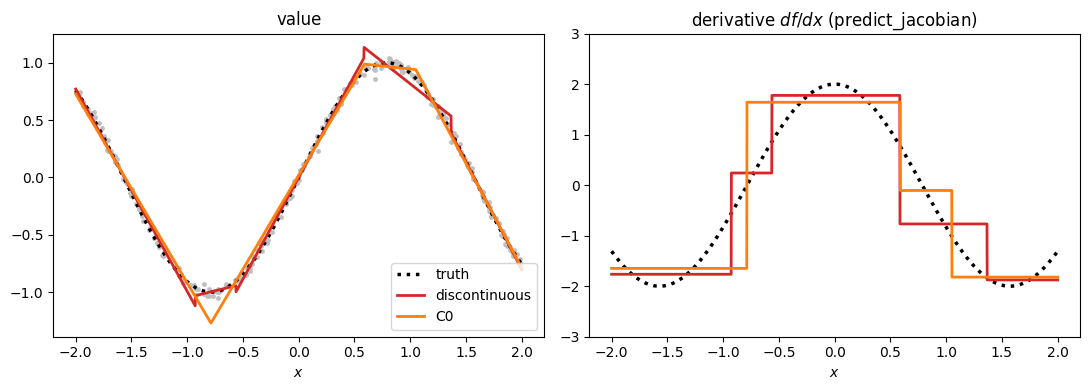

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X1[:, 0], y1, s=6, color="0.75")
for ax, deriv in zip(axes, (False, True)):
    ax.plot(xg[:, 0], df1(xg) if deriv else f1(xg), "k:", lw=2.5, label="truth")
    for name, mod, c in (("discontinuous", plain, "C3"), ("C0", c0, "C1")):
        v = mod.predict_jacobian(xg, hard=True)[:, 0] if deriv else mod.predict(xg, hard=True)
        ax.plot(xg[:, 0], v, color=c, lw=2, label=name)
axes[0].set(xlabel="$x$", title="value")
axes[1].set(xlabel="$x$", title="derivative $df/dx$ (predict_jacobian)", ylim=(-3, 3))
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

The C0 tree has no jumps in value, so a MILP cannot exploit a gap between leaves. Its derivative is still a staircase with a jump at every split, and that is as smooth as an exact MILP surrogate can get. The C0 tree is exactly the hinging-hyperplanes model

$$
f(x) = \theta_0^\top [1, x] + \sum_{d=1}^{D} c_d \max\bigl(0, h_d(x)\bigr), \qquad h_d(x) = w_d^\top x + b_d,
$$

with one hyperplane per depth. `export.to_pyomo` embeds it exactly, either as a disjunction over its $2^D$ leaves (the default) or, with `formulation="pwl"`, in this hinge form with one binary per hyperplane (see the [Pyomo notebook](pyomo_embedding) for the leaf form).

## Part 2: a C1 tree with `smoothness=1`

Why quadratic pieces: two quadratic leaves $q_1, q_2$ meeting on $h(x) = 0$ join with a continuous gradient only if $q_1 - q_2 = \alpha\, h(x)^2$. `smoothness=1` uses the simplest construction of this kind that keeps the C0 tree's structure. Each $\max(0, h)$ becomes

$$
\phi_\varepsilon(h) = \begin{cases} 0 & h \le -\varepsilon \\ \dfrac{(h + \varepsilon)^2}{4\varepsilon} & |h| < \varepsilon \\ h & h \ge \varepsilon \end{cases}
\qquad
\phi_\varepsilon'(h) = \operatorname{clip}\!\Bigl(\frac{h + \varepsilon}{2\varepsilon}, 0, 1\Bigr).
$$

Outside a band of half-width $\varepsilon_d$ around each hyperplane, the model is exactly an affine tree. Inside a band it is quadratic, and the gradient turns from one leaf's slope to the other's. Because $\phi_\varepsilon'' = 1/(2\varepsilon)$ in the band, $\varepsilon_d$ bounds the curvature. As $\varepsilon \to 0$ the C0 hinge model comes back.

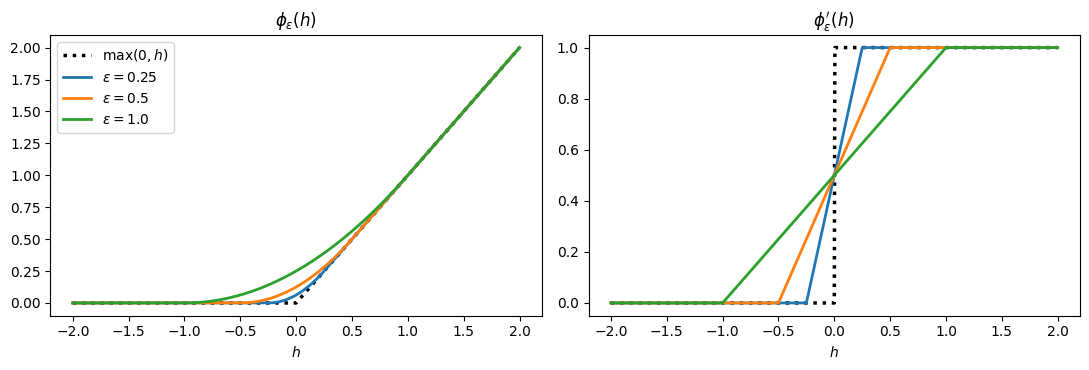

In [4]:
def phi(h, eps):
    return np.where(h <= -eps, 0.0, np.where(h >= eps, h, (h + eps) ** 2 / (4 * eps)))

hs = np.linspace(-2, 2, 801)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(hs, np.maximum(hs, 0), "k:", lw=2.5, label=r"$\max(0, h)$")
axes[1].plot(hs, (hs > 0).astype(float), "k:", lw=2.5, label=r"step")
for eps in (0.25, 0.5, 1.0):
    axes[0].plot(hs, phi(hs, eps), lw=2, label=rf"$\varepsilon = {eps}$")
    axes[1].plot(hs, np.clip((hs + eps) / (2 * eps), 0, 1), lw=2, label=rf"$\varepsilon = {eps}$")
axes[0].set(xlabel="$h$", title=r"$\phi_\varepsilon(h)$")
axes[1].set(xlabel="$h$", title=r"$\phi_\varepsilon'(h)$")
axes[0].legend()
plt.tight_layout()
plt.show()

Hardening with `smoothness=1` first does the C0 fit. It then fits the hyperplanes, one band half-width per depth and output, and the coefficients together by least squares (L-BFGS-B, starting from both wide and narrow bands). Two settings control the result:

- `band_bounds` (default `(0.05, 3.0)`, a distance in standardized input space) bounds the band half-widths. The lower end caps the curvature. A much narrower band is C1 only in name: the gradient turns so quickly that IPOPT sees a kink and can fail to converge.
- `hinge_ridge` (default $10^{-2}$ for C1) is a small ridge on the hinge coefficients. Without it, the fit sometimes uses two nearly parallel hyperplanes with large coefficients of opposite sign that cancel into a gentle curve. That function is fine, but the error bound of Part 3 scales with $|c_d|$, and in a prototype of this notebook the cancellation ($c_d \approx -217$ and $+283$) made it about thirty times larger.

### One input: $\sin 2x$

In [5]:
c1 = DifferentiableTreeRegressor(tied_splits=True, continuous=True, smoothness=1, **common).fit(X1, y1)

c0_g, c1_g = c0.predict(xg, hard=True), c1.predict(xg, hard=True)
dc0_g = c0.predict_jacobian(xg, hard=True)[:, 0]
dc1_g = c1.predict_jacobian(xg, hard=True)[:, 0]
print(f"value RMSE:      C0 {rmse(c0_g, f1(xg)):.4f}   C1 {rmse(c1_g, f1(xg)):.4f}")
print(f"derivative RMSE: C0 {rmse(dc0_g, df1(xg)):.4f}   C1 {rmse(dc1_g, df1(xg)):.4f}")
print("max gradient jump:", c1.hardening_report_["max_gradient_jump"])
print("band half-widths (standardized x):", c1.hardening_report_["band_halfwidth"].ravel().round(3))

value RMSE:      C0 0.0646   C1 0.0114
derivative RMSE: C0 0.5308   C1 0.1280
max gradient jump: [0.]
band half-widths (standardized x): [0.422 0.407 0.389]


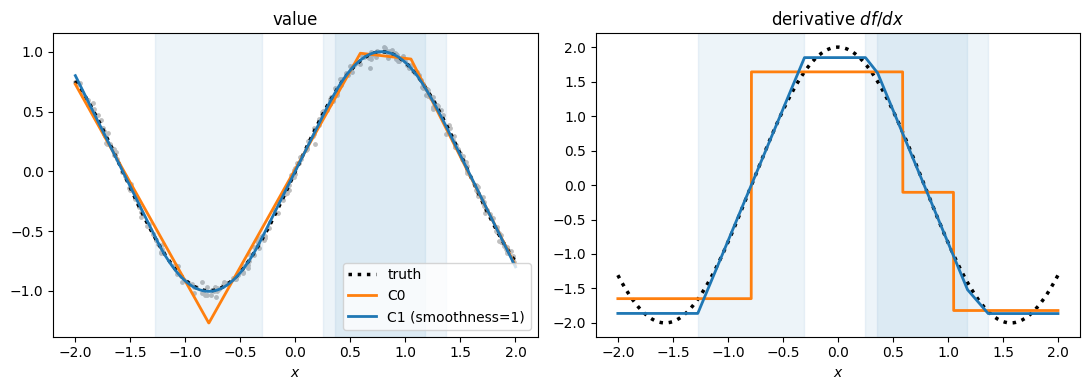

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X1[:, 0], y1, s=6, color="0.75")
for ax, (tr, a, b) in zip(axes, ((f1(xg), c0_g, c1_g), (df1(xg), dc0_g, dc1_g))):
    ax.plot(xg[:, 0], tr, "k:", lw=2.5, label="truth")
    ax.plot(xg[:, 0], a, color="C1", lw=2, label="C0")
    ax.plot(xg[:, 0], b, color="C0", lw=2, label="C1 (smoothness=1)")
# Shade the quadratic bands |h_d(x)| < eps_d, mapped back to original x.
h = c1.hinge_
for w, b0, e in zip(h["W"][:, 0], h["b"], h["eps"][:, 0]):
    band = np.sort([(-e - b0) / w, (e - b0) / w]) * c1.x_std_[0] + c1.x_mean_[0]
    for ax in axes:
        ax.axvspan(*band, color="C0", alpha=0.08)
axes[0].set(xlabel="$x$", title="value")
axes[1].set(xlabel="$x$", title="derivative $df/dx$")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

The shaded intervals are the bands where the C1 model is quadratic (from `hinge_`, the fitted hinge form in standardized units). The C1 derivative is continuous and piecewise linear, and it follows $2 \cos 2x$ much more closely than the C0 staircase, with the same three hyperplanes.

### Two inputs: a Gaussian bump

$f(x) = \exp(-\lVert x \rVert^2)$ on $[-2, 2]^2$ is hard for a hinge model, which needs many planes to wrap around a round peak. We fit depth 4 and depth 6 trees, C0 and C1. The depth-4 C1 model is the one we embed in a MILP in Part 3.

In [7]:
f2 = lambda X: np.exp(-np.sum(X**2, axis=1))
df2 = lambda X: -2 * X * f2(X)[:, None]

rng = np.random.default_rng(1)
lo2, hi2 = np.array([-2.0, -2.0]), np.array([2.0, 2.0])
X2 = rng.uniform(lo2, hi2, (400, 2))
y2 = f2(X2) + 0.01 * rng.normal(size=400)
X2_te = rng.uniform(lo2, hi2, (4000, 2))

tied = dict(leaf_type="affine", tied_splits=True, continuous=True, hardening=True,
            n_epochs=200, random_state=0)
fits2 = {}
for depth in (4, 6):
    m0 = DifferentiableTreeRegressor(depth=depth, **tied).fit(X2, y2)
    m1 = DifferentiableTreeRegressor(depth=depth, smoothness=1, **tied).fit(X2, y2)
    fits2[depth] = (m0, m1)
    print(f"depth {depth}: RMSE C0 {rmse(m0.predict(X2_te, hard=True), f2(X2_te)):.4f}   "
          f"C1 {rmse(m1.predict(X2_te, hard=True), f2(X2_te)):.4f}   "
          f"gradient RMSE C0 {rmse(m0.predict_jacobian(X2_te, hard=True), df2(X2_te)):.4f}   "
          f"C1 {rmse(m1.predict_jacobian(X2_te, hard=True), df2(X2_te)):.4f}")
    print(f"         band half-widths {m1.hardening_report_['band_halfwidth'].ravel().round(2)}")

depth 4: RMSE C0 0.0920   C1 0.0725   gradient RMSE C0 0.2341   C1 0.1845
         band half-widths [0.42 1.37 0.48 0.05]


depth 6: RMSE C0 0.0717   C1 0.0237   gradient RMSE C0 0.2135   C1 0.0820
         band half-widths [0.22 0.56 0.45 1.71 0.57 0.23]


The maps below show the depth-6 fits. In the top row the C0 model's facets meet in creases, and the C1 model rounds them. The bottom row shows $\lVert \nabla f \rVert$ from `predict_jacobian`: the C0 gradient is constant on each cell and jumps across every line, while the C1 gradient varies continuously.

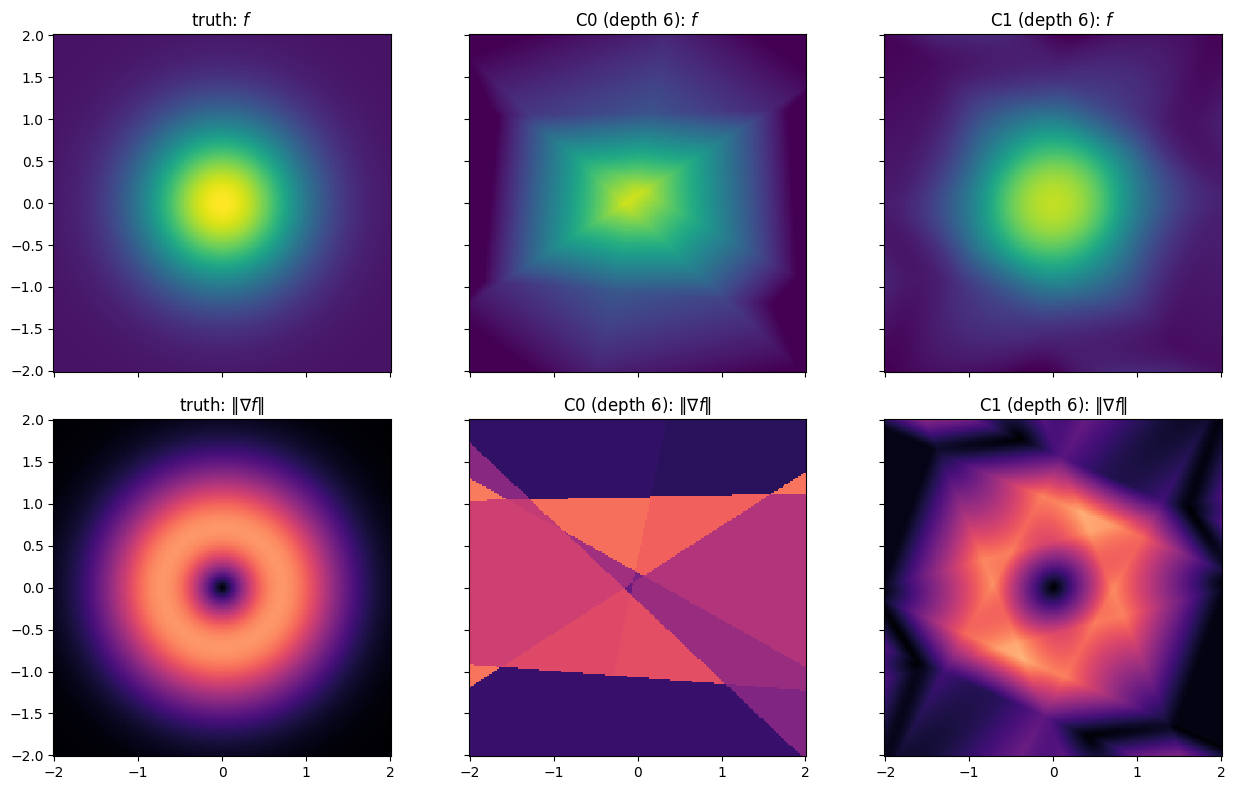

In [8]:
m0, m1 = fits2[6]
g0, g1 = np.meshgrid(np.linspace(-2, 2, 201), np.linspace(-2, 2, 201))
G = np.c_[g0.ravel(), g1.ravel()]
panels = [
    ("truth", f2(G), np.linalg.norm(df2(G), axis=1)),
    ("C0 (depth 6)", m0.predict(G, hard=True), np.linalg.norm(m0.predict_jacobian(G, hard=True), axis=1)),
    ("C1 (depth 6)", m1.predict(G, hard=True), np.linalg.norm(m1.predict_jacobian(G, hard=True), axis=1)),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
for j, (title, val, gn) in enumerate(panels):
    axes[0, j].pcolormesh(g0, g1, val.reshape(g0.shape), shading="auto", cmap="viridis", vmin=-0.05, vmax=1.0)
    axes[1, j].pcolormesh(g0, g1, gn.reshape(g0.shape), shading="auto", cmap="magma", vmin=0, vmax=1.1)
    axes[0, j].set_title(f"{title}: $f$")
    axes[1, j].set_title(rf"{title}: $\|\nabla f\|$")
for ax in axes.ravel():
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

At depth 6 the C1 model is about three times more accurate than the C0 model (RMSE 0.024 against 0.072), and its gradient error is less than half as large (0.08 against 0.21). Its peak is round, and its gradient vanishes at the centre as the truth's does. Creases are still visible in the gradient map where bands meet, but none of them is a jump. The hyperplane fit is nonconvex and starts from the C0 solution, so it can stop in a worse local minimum. In early experiments the depth-6 error varied several-fold across data seeds.

### When the truth has kinks

Smoothing should not hurt much when the C0 model is already right. $f(x) = \lvert x_0 \rvert + x_1 + \max(x_2, 0)$ is itself a hinge model with two kinks. Its gradient really does jump, so the best C1 fit makes the bands narrow, down to the lower end of `band_bounds`. Rounding each kink over a band of half-width 0.05 costs some accuracy, which is the price of a continuous gradient. Lowering the bound does not change much here, because the fit settles at bands of about 0.04 on its own.

In [9]:
f3 = lambda X: np.abs(X[:, 0]) + X[:, 1] + np.maximum(X[:, 2], 0)
rng = np.random.default_rng(2)
X3 = rng.uniform(-2, 2, (400, 3))
y3 = f3(X3) + 0.01 * rng.normal(size=400)
X3_te = rng.uniform(-2, 2, (4000, 3))
for label, kw in (("C0", {}), ("C1", dict(smoothness=1)), ("C1, band_bounds=(1e-3, 3)", dict(smoothness=1, band_bounds=(1e-3, 3.0)))):
    m = DifferentiableTreeRegressor(depth=3, **tied, **kw).fit(X3, y3)
    bands = m.hardening_report_.get("band_halfwidth")
    print(f"{label:>26s}: RMSE {rmse(m.predict(X3_te, hard=True), f3(X3_te)):.4f}"
          + ("" if bands is None else f"   bands {bands.ravel().round(3)}"))

                        C0: RMSE 0.0024


                        C1: RMSE 0.0046   bands [0.05 0.05 0.05]


 C1, band_bounds=(1e-3, 3): RMSE 0.0048   bands [0.041 0.043 0.05 ]


### Summary across test functions

Held-out RMSE on the same three functions as the continuity table in the surrogates guide, at depths 3 and 4.

In [10]:
cases = {
    "|x0| + x1 + max(x2, 0)": (f3, 3, 400, 0.01),
    "Gaussian bump (2 inputs)": (f2, 2, 400, 0.01),
    "sin 2x (1 input)": (f1, 1, 300, 0.03),
}
print(f"{'function':<26s} {'depth':>5s} {'C0':>8s} {'C1':>8s}")
for name, (f, p, n, noise) in cases.items():
    rng = np.random.default_rng(0)
    X = rng.uniform(-2, 2, (n, p)); y = f(X) + noise * rng.normal(size=n)
    Xt = rng.uniform(-2, 2, (4000, p))
    for depth in (3, 4):
        r = [rmse(DifferentiableTreeRegressor(depth=depth, smoothness=s, **tied).fit(X, y).predict(Xt, hard=True), f(Xt))
             for s in (0, 1)]
        print(f"{name:<26s} {depth:>5d} {r[0]:8.4f} {r[1]:8.4f}")

function                   depth       C0       C1


|x0| + x1 + max(x2, 0)         3   0.0023   0.0033


|x0| + x1 + max(x2, 0)         4   0.0027   0.0037


Gaussian bump (2 inputs)       3   0.0920   0.0907


Gaussian bump (2 inputs)       4   0.0871   0.0739


sin 2x (1 input)               3   0.0643   0.0116


sin 2x (1 input)               4   0.0309   0.0109


## Part 3: a MILP for the C1 model

A C1 model is not piecewise linear, so the leaf-based exports refuse it rather than export leaf models that describe it only outside its bands:

In [11]:
m0, m1 = fits2[4]
try:
    export.to_pyomo(m1)
except ValueError as e:
    print(e)

to_pyomo exports a piecewise-affine tree, but this model is C1 (smoothness=1) and is quadratic near its splits. Use to_pyomo(..., formulation='pwl', K=...) for a MILP approximation with a guaranteed error bound, or formulation='smooth' for an NLP.


Each smoothed hinge $\phi_{\varepsilon_d}(h_d)$ is a function of one scalar, so a one-dimensional piecewise-linear approximation per hyperplane is enough. No triangulation of the input space is needed. Put $K + 1$ equally spaced breakpoints $t_0 = -\varepsilon, \dots, t_K = \varepsilon$ across the band and interpolate. Outside the band $\phi_\varepsilon$ is already linear, so the interpolant is exact there. Writing $s_k$ for the slope on segment $k$ (with $s_0 = 0$ and $s_{K+1} = 1$ outside the band), the interpolant is itself a sum of hinges at the breakpoints:

$$
\hat\phi_K(h) = \sum_{k=0}^{K} a_k \max(0, h - t_k), \qquad a_k = s_{k+1} - s_k \ge 0.
$$

So the approximation is a C0 hinge model with $K + 1$ parallel copies of each hyperplane, and it embeds exactly in a MILP with one binary per hinge term.

**Error bound.** On a segment of length $L = 2\varepsilon / K$, linear interpolation of a function with constant second derivative $1/(2\varepsilon)$ is off by at most $\varepsilon / (4K^2)$. Since $\phi_\varepsilon$ is convex, the interpolant lies above it. Summing over hyperplanes, at every $x$

$$
-\sum_d \max(-c_d, 0)\, \frac{\varepsilon_d}{4K^2} \;\le\; \hat f_K(x) - f(x) \;\le\; \sum_d \max(c_d, 0)\, \frac{\varepsilon_d}{4K^2}.
$$

`export.pwl_error_bound(model, K)` returns these two sums (`under`, `over`) in original units, and `bound`, the larger of the two. The table compares the bound with the largest deviation actually observed on a grid, using `to_pyomo(..., formulation="pwl")` with the inputs fixed at each grid point. That takes one MILP per point, so we use a coarse grid.

In [12]:
solver = pyo.SolverFactory("appsi_highs")

def pwl_values(model, K, X):
    # Evaluate the "pwl" formulation at fixed inputs by solving it.
    b = export.to_pyomo(model, bounds=(lo2, hi2), formulation="pwl", K=K)
    M = b.model()
    M.obj = pyo.Objective(expr=0)
    out = []
    for x in X:
        for v, xv in zip(b.x.values(), x):
            v.fix(xv)
        solver.solve(M)
        out.append(pyo.value(b.y[0]))
    return np.array(out), b

gx, gy = np.meshgrid(np.linspace(-2, 2, 21), np.linspace(-2, 2, 21))
Xc = np.c_[gx.ravel(), gy.ravel()]
c1_Xc = m1.predict(Xc, hard=True)
print(f"{'K':>3s} {'binaries':>9s} {'bound':>9s} {'over':>9s} {'under':>9s} {'observed max |pwl - C1|':>24s}")
for K in (1, 2, 4, 8, 16):
    vals, b = pwl_values(m1, K, Xc)
    eb = b.error_bound
    n_bin = sum(1 for v in b.on.values() if not v.fixed)
    print(f"{K:>3d} {n_bin:>9d} {eb['bound'][0]:>9.2e} {eb['over'][0]:>9.2e} {eb['under'][0]:>9.2e} "
          f"{np.max(np.abs(vals - c1_Xc)):>24.2e}")

  K  binaries     bound      over     under  observed max |pwl - C1|


  1         8  8.95e-01  8.95e-01  3.56e-01                 8.93e-01


  2        12  2.24e-01  2.24e-01  8.90e-02                 2.24e-01


  4        20  5.59e-02  5.59e-02  2.22e-02                 5.59e-02


  8        36  1.40e-02  1.40e-02  5.56e-03                 1.40e-02


 16        68  3.49e-03  3.49e-03  1.39e-03                 3.49e-03


The observed deviation equals the bound to three digits at every $K$, so the bound is tight (it is attained at the midpoint of a segment of the dominant hinge's band). It falls as $1/K^2$, while the number of binaries grows as $D(K+1)$. At $K = 8$ the PWL model is within 0.014 of the C1 model, a fifth of the C1 model's own fitting error (RMSE 0.072). A curved surrogate genuinely needs this many segments: linear interpolation over a segment of length $L$ of a function with curvature $\kappa$ is off by $\kappa L^2 / 8$, so the tolerance you want sets the breakpoint spacing.

### Optimizing: MILP, then IPOPT on the C1 model

As a test problem we look for the peak of the bump surrogate (the true peak is $f = 1$ at the origin). The MILP solves the PWL model globally. Because $\hat f_K - f$ lies in $[-\text{under}, \text{over}]$ everywhere, the MILP's optimal value is within that interval of the C1 model's global maximum. Its solution then starts IPOPT on the C1 model itself (`formulation="smooth"`, no binaries), which is valid input for a smooth NLP solver because the gradient is continuous.

In [13]:
K = 8
M = pyo.ConcreteModel()
b = export.to_pyomo(m1, M, bounds=(lo2, hi2), formulation="pwl", K=K)
M.obj = pyo.Objective(expr=b.y[0], sense=pyo.maximize)
solver.solve(M)
x_milp = np.array([pyo.value(v) for v in b.x.values()])
n_bin = sum(1 for v in b.on.values() if not v.fixed)
print(f"MILP (K={K}, {n_bin} binaries): x = {np.round(x_milp, 4)}, PWL value {pyo.value(M.obj):.5f}")
print(f"  C1 model at x_milp: {m1.predict(x_milp[None], hard=True)[0]:.5f}   "
      f"(error in [-{b.error_bound['under'][0]:.2e}, {b.error_bound['over'][0]:.2e}])")

N = pyo.ConcreteModel()
s = export.to_pyomo(m1, N, bounds=(lo2, hi2), formulation="smooth")
for v, x0 in zip(s.x.values(), x_milp):
    v.set_value(x0)
N.obj = pyo.Objective(expr=s.y[0], sense=pyo.maximize)
res = pyo.SolverFactory("ipopt").solve(N)
x_nlp = np.array([pyo.value(v) for v in s.x.values()])
print(f"IPOPT on C1 ({res.solver.termination_condition}): x = {np.round(x_nlp, 4)}, "
      f"C1 value {pyo.value(N.obj):.5f}, "
      f"gradient norm {np.linalg.norm(m1.predict_jacobian(x_nlp[None], hard=True)):.1e}")
print(f"  true f at x_milp {f2(x_milp[None])[0]:.4f}, at x_nlp {f2(x_nlp[None])[0]:.4f} (true max 1.0)")

MILP (K=8, 36 binaries): x = [-0.0101  0.0199], PWL value 0.82744
  C1 model at x_milp: 0.82582   (error in [-5.56e-03, 1.40e-02])


IPOPT on C1 (optimal): x = [-0.0079  0.0154], C1 value 0.82583, gradient norm 2.2e-11
  true f at x_milp 0.9995, at x_nlp 0.9997 (true max 1.0)


The MILP value and the C1 value at its solution agree to within the bound, and IPOPT converges from there to a stationary point of the C1 model. With the C0 tree the second step would not be meaningful, because the optimum of a piecewise-affine model sits at a vertex where the gradient is undefined. The remaining gap between the surrogate's peak value and the true value of 1 is surrogate error. It comes from data and model capacity, not from the optimization.

## Summary

| | C0 (`smoothness=0`) | C1 (`smoothness=1`) |
|---|---|---|
| model | hinge model, affine leaves | affine outside bands, quadratic inside |
| gradient | jumps at every split | continuous |
| exact MILP | yes (`"tree"` or `"pwl"`) | no |
| MILP approximation | n/a | `"pwl"` with $K$: error $\le$ `pwl_error_bound` |
| NLP | `"smooth"` (only C0) | `"smooth"` (C1) |

A natural workflow for a C1 surrogate is to solve the `"pwl"` MILP globally with a $K$ chosen from `pwl_error_bound`, then polish with IPOPT on `"smooth"`.